In [1]:
from pathlib import Path
import importlib

import numpy as np
import pandas as pd

DATA_DIR = Path("out")
FIGURES_DIR = Path("figures")
LOGS_DIR = Path('logs')

utils = importlib.import_module('utils')
importlib.reload(utils)

DEVICES_PER_WORKERS = 4

### N-Body

In [57]:
DATE='080826'

benchs = [f'{DATE}_nbody_{i}_workers' for i in range(1, 9)]


all_df = pd.concat([
    utils.load_data(DATA_DIR/f"{bench}.pkl")[0] for i, bench in enumerate(benchs, start=1)
])

all_df['devices_per_worker'] = all_df['dlist'].apply(lambda x: len(x.split(',')))
all_df['num_devices'] = all_df['devices_per_worker'] * all_df['workers']

all_df.drop(columns=['dlist', 'hosts', 'time', 'container'], inplace=True)

all_df


df_runtime_4dev = all_df[all_df['num_devices'] == DEVICES_PER_WORKERS].copy()
df_runtime_4dev = utils.aggregate_data(df_runtime_4dev, ['name', 'workers', 'num_devices'])

df_runtime_4dev = df_runtime_4dev.rename(columns={'runtime_mean': 'runtime_4dev'})
df_runtime_4dev = df_runtime_4dev.drop(columns=['num_devices', 'workers', 'runtime_std'])

agg_df = pd.merge(all_df, df_runtime_4dev, on=['name'], how='right')
agg_df['speedup'] = agg_df['runtime_4dev']/agg_df['runtime']

# agg_df.query('name == "mpp"')

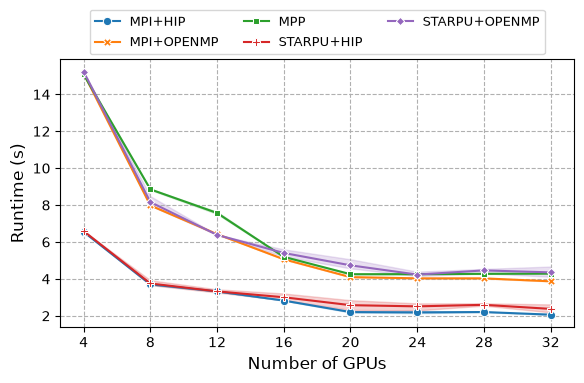

In [58]:
# agg_df = agg_df.query('( devices_per_worker == 4 | num_devices == 1 ) & name == "MPP"')
# agg_df = agg_df.query('num_devices <= 64')

# agg_df['name'] = agg_df['name'].apply(lambda x: 'HIOFF' if x == 'hoff' else 'original')
agg_df['name'] = agg_df['name'].apply(lambda name: 'MPI+OpenMP' if 'mpi-openmp' in name else 'MPI+HIP' if 'mpi-hip' in name else name)
agg_df['name'] = agg_df['name'].apply(lambda name: 'STARPU+OpenMP' if 'starpu-openmp' in name else 'STARPU+HIP' if 'starpu-hip' in name else name)

agg_df['name'] = agg_df['name'].str.upper()

plot_meta = utils.PlotMeta(
    x_axis='num_devices',
    y_axis='runtime',
    hue='name',
    style='name',
    xlabel='Number of GPUs',
    ylabel='Runtime (s)',
    # xticks=[],
    xticks=agg_df['num_devices'].astype(str).unique(),
    # yticks=list(np.linspace(1, 64, num=8, dtype=int)),
    yticks=[],
    legend_title='',
    legend_labels=[],
)

utils.generic_line_plot_err_bar_3(
    dataset=agg_df,
    title='',
    output_file=FIGURES_DIR/f'{DATE}_nbody_strong_runtime.pdf',
    plot_meta=plot_meta,
    dashes=False,
    outside_legend=True
)

# print(agg_df['speedup'].max())

### Task-Bench

In [3]:
def process_df(df, workers):
    df['workers'] = workers
    return df

In [4]:
importlib.reload(utils)

scaling = 'ss'  # 'ws' for weak scaling, 'ss' for strong scaling
DATE = '130826'

benchs = [f'{DATE}_tb_gpu_{i}_workers' for i in range(1, 11)]

all_df = pd.concat([
    process_df(utils.load_data(DATA_DIR/f"{bench}.pkl")[0], i) for i, bench in enumerate(benchs, start=1) if (DATA_DIR/f"{bench}.pkl").exists()
])

all_df['devices_per_worker'] = all_df['dlist'].apply(lambda x: len(x.split(',')))
all_df['num_devices'] = all_df['devices_per_worker'] * all_df['workers']

all_df.drop(columns=['hosts', 'time', 'container', 'vcis', 'version', 'kernel', 'output'], inplace=True)

# all_df

# dev1_df = process_df(utils.load_data(DATA_DIR/"300326_mi210_ss_1_device_mpp.pkl")[0], 1)
# if 'total_tasks' not in dev1_df.columns:
#     dev1_df['total_tasks'] = 10 
# mpp_1dev_df = dev1_df.copy(deep=True)

# dev1_df = process_df(utils.load_data(DATA_DIR/"300326_mi210_ss_1_device_mpi.pkl")[0], 1)
# if 'total_tasks' not in dev1_df.columns:
#     dev1_df['total_tasks'] = 10 
# mpi_1dev_df = dev1_df.copy(deep=True)
# mpi_1dev_df['sys'] = 'mpi+openmp'

# all_df = pd.concat([all_df, mpp_1dev_df, mpi_1dev_df])

# agg_all_df = all_df.groupby(by=['sys', 'accl', 'devices', 'type', 'output', 'size', 'total_flops', 'total_tasks']).agg(
#     runtime_mean=('wall_time', 'mean'),
#     runtime_std=('wall_time', 'std')
# ).reset_index()




agg_all_df = all_df.copy(deep=True)
agg_all_df['runtime_mean'] = agg_all_df['wall_time']

agg_all_df['tflops_per_sec'] = agg_all_df['total_flops'] * np.pow(1/10, 12) / agg_all_df['runtime_mean']
agg_all_df['flops_per_task'] = agg_all_df['total_flops'] / agg_all_df['total_tasks']

agg_all_df

# agg_all_df_max_flops_per_device = agg_all_df.groupby(
#     by=['accl', 'devices', 'type', 'output'], as_index=False
# )['tflops_per_sec'].max()
# agg_all_df_max_flops_per_device.rename(columns={'tflops_per_sec': 'max_tflops_per_sec'}, inplace=True)
# agg_all_df = agg_all_df.merge(agg_all_df_max_flops_per_device, on=['accl', 'devices', 'type', 'output'])
# agg_all_df['efficiency'] = agg_all_df['tflops_per_sec'] * 100 / agg_all_df['max_tflops_per_sec']
# agg_all_df['task_granularity'] = agg_all_df['runtime_mean'] * agg_all_df['devices'] * np.pow(10, 3) / agg_all_df['total_tasks']
# agg_all_df['size'] = 2**agg_all_df['size']
# agg_all_df['output'] = 2**agg_all_df['output']
# agg_all_df['config'] = (
#     agg_all_df['sys'].str.upper()
# )

# metg_target = 'task_granularity'

# metg = lambda x: utils.find_metg(x, x_data=metg_target, y_data='efficiency', method=2)

# # Get METG(50%)
# metg_df = agg_all_df[['config', 'sys', 'accl', 'devices',  'output', 'type', metg_target, 'efficiency']].groupby(
#     ['config', 'sys', 'accl', 'devices', 'output', 'type']).apply(metg, include_groups=False
# ).reset_index()


,name,nblocks,type,dlist,total_deps,radix,workers,tpblock,total_flops,width,wall_time,size,total_tasks,total_bytes,hht,devices_per_worker,num_devices,runtime_mean,tflops_per_sec,flops_per_task
0,mpi_openmp,1024,fft,"0,1,2,3",996,5,1,512,7036874417766400,40,90.25801,20,400,0,48,4,4,90.25801,77.963988,17592186044416.0
1,mpi_openmp,1024,fft,"0,1,2,3",996,5,1,512,7036874417766400,40,90.23701,20,400,0,48,4,4,90.23701,77.982132,17592186044416.0
2,mpi_openmp,1024,stencil_1d,"0,1,2,3",1180,5,1,512,7036874417766400,40,90.25701,20,400,0,48,4,4,90.25701,77.964852,17592186044416.0
3,mpi_openmp,1024,stencil_1d,"0,1,2,3",1180,5,1,512,7036874417766400,40,90.23,20,400,0,48,4,4,90.23,77.98819,17592186044416.0
4,mpi_openmp,1024,stencil_1d,"0,1,2,3",1180,5,1,512,7036874417766400,40,90.239,20,400,0,48,4,4,90.239,77.980412,17592186044416.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40,mpp,1024,tree,"0,1,2,3",223,5,8,512,3923057487904768,40,11.77702,20,223,0,32,4,32,11.77702,333.111219,17592186044416.0
41,mpp,1024,tree,"0,1,2,3",223,5,8,512,3923057487904768,40,11.73082,20,223,0,32,4,32,11.73082,334.423125,17592186044416.0
42,mpp,1024,nearest,"0,1,2,3",1940,5,8,512,7036874417766400,40,24.6011,20,400,0,32,4,32,24.6011,286.039015,17592186044416.0
43,mpp,1024,nearest,"0,1,2,3",1940,5,8,512,7036874417766400,40,22.08099,20,400,0,32,4,32,22.08099,318.684734,17592186044416.0


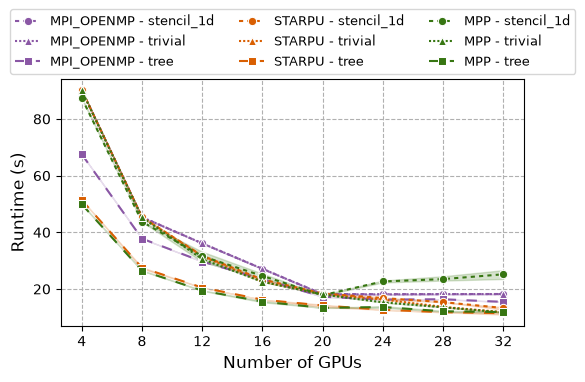

In [6]:
# agg_df = agg_df.query('( devices_per_worker == 4 | num_devices == 1 ) & name == "MPP"')
# agg_df = agg_df.query('num_devices <= 64')

# agg_df['name'] = agg_df['name'].apply(lambda x: 'HIOFF' if x == 'hoff' else 'original')
agg_all_df['name'] = agg_all_df['name'].str.upper()
types = ['stencil_1d', 'trivial', 'tree']

agg_all_df = agg_all_df.query('type in @types').copy(deep=True)

agg_all_df['config'] = agg_all_df['name'] + ' - ' + agg_all_df['type']

# agg_all_df['num_devices'] = agg_all_df['num_devices'].fillna(20)

plot_meta = utils.PlotMeta(
    x_axis='num_devices',
    y_axis='runtime_mean',
    hue='config',
    style='config',
    xlabel='Number of GPUs',
    ylabel='Runtime (s)',
    # xticks=[],
    xticks=agg_all_df['num_devices'].astype(str).unique(),
    # yticks=list(np.linspace(1, 64, num=8, dtype=int)),
    yticks=[],
    legend_title='',
    legend_labels=[],
)

utils.generic_line_plot_err_bar_3(
    dataset=agg_all_df,
    title='',
    output_file=FIGURES_DIR/f'{DATE}_taskbench_runtime.pdf',
    plot_meta=plot_meta,
    dashes=True,
    outside_legend=True,
    tricolor_system=True
)

# print(agg_df['speedup'].max())

In [13]:
importlib.reload(utils)

scaling = 'ss'  # 'ws' for weak scaling, 'ss' for strong scaling
DATE = '130826'

benchs = [f'{DATE}_tb_gpu_ws_{i}_workers' for i in range(1, 11)]

all_df = pd.concat([
    process_df(utils.load_data(DATA_DIR/f"{bench}.pkl")[0], i) for i, bench in enumerate(benchs, start=1) if (DATA_DIR/f"{bench}.pkl").exists()
])

all_df['devices_per_worker'] = all_df['dlist'].apply(lambda x: len(x.split(',')))
all_df['num_devices'] = all_df['devices_per_worker'] * all_df['workers']

all_df.drop(columns=['hosts', 'time', 'container', 'vcis', 'version', 'kernel'], inplace=True)
all_df['output'] = pd.to_numeric(all_df['output'], errors='coerce').fillna(4)

# all_df

# dev1_df = process_df(utils.load_data(DATA_DIR/"300326_mi210_ss_1_device_mpp.pkl")[0], 1)
# if 'total_tasks' not in dev1_df.columns:
#     dev1_df['total_tasks'] = 10 
# mpp_1dev_df = dev1_df.copy(deep=True)

# dev1_df = process_df(utils.load_data(DATA_DIR/"300326_mi210_ss_1_device_mpi.pkl")[0], 1)
# if 'total_tasks' not in dev1_df.columns:
#     dev1_df['total_tasks'] = 10 
# mpi_1dev_df = dev1_df.copy(deep=True)
# mpi_1dev_df['sys'] = 'mpi+openmp'

# all_df = pd.concat([all_df, mpp_1dev_df, mpi_1dev_df])

# agg_all_df = all_df.groupby(by=['sys', 'accl', 'devices', 'type', 'output', 'size', 'total_flops', 'total_tasks']).agg(
#     runtime_mean=('wall_time', 'mean'),
#     runtime_std=('wall_time', 'std')
# ).reset_index()




agg_all_df = all_df.copy(deep=True)
agg_all_df['runtime_mean'] = agg_all_df['wall_time']

agg_all_df['tflops_per_sec'] = agg_all_df['total_flops'] * np.pow(1/10, 12) / agg_all_df['runtime_mean']
agg_all_df['flops_per_task'] = agg_all_df['total_flops'] / agg_all_df['total_tasks']


agg_all_df_max_flops_per_device = agg_all_df.groupby(
    by=['name', 'num_devices', 'type', 'output'], as_index=False
)['tflops_per_sec'].max()


agg_all_df_max_flops_per_device.rename(columns={'tflops_per_sec': 'max_tflops_per_sec'}, inplace=True)
agg_all_df = agg_all_df.merge(agg_all_df_max_flops_per_device, on=['name', 'num_devices', 'type', 'output'])
agg_all_df['efficiency'] = agg_all_df['tflops_per_sec'] * 100 / agg_all_df['max_tflops_per_sec']
agg_all_df['task_granularity'] = agg_all_df['runtime_mean'] * agg_all_df['num_devices'] * np.pow(10, 3) / agg_all_df['total_tasks']
agg_all_df['size'] = 2**agg_all_df['size']
agg_all_df['output'] = 2**agg_all_df['output']
# agg_all_df['config'] = (
#     agg_all_df['sys'].str.upper()
# )

agg_all_df

metg_target = 'task_granularity'

metg = lambda x: utils.find_metg(x, x_data=metg_target, y_data='efficiency', method=2)

# # Get METG(50%)
metg_df = agg_all_df[['name', 'num_devices',  'output', 'type', metg_target, 'efficiency']].groupby(
    ['name', 'num_devices', 'output', 'type']).apply(metg, include_groups=False
).reset_index()

metg_df


,name,num_devices,output,type,metg
0,mpi_openmp,4,16.0,fft,54.077152
1,mpi_openmp,4,16.0,nearest,54.333709
2,mpi_openmp,4,16.0,stencil_1d,53.437901
3,mpi_openmp,4,16.0,tree,20.740281
4,mpi_openmp,4,16.0,trivial,15.331109
...,...,...,...,...,...
115,starpu,32,16.0,fft,22.688178
116,starpu,32,16.0,nearest,22.269216
117,starpu,32,16.0,stencil_1d,22.186361
118,starpu,32,16.0,tree,67.272970


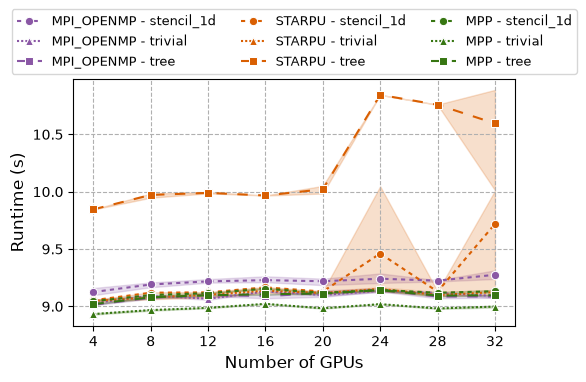

In [11]:
# agg_df = agg_df.query('( devices_per_worker == 4 | num_devices == 1 ) & name == "MPP"')
# agg_df = agg_df.query('num_devices <= 64')

# agg_df['name'] = agg_df['name'].apply(lambda x: 'HIOFF' if x == 'hoff' else 'original')
agg_all_df['name'] = agg_all_df['name'].str.upper()
types = ['stencil_1d', 'trivial', 'tree']
size = 2**20
agg_all_df = agg_all_df.query('type in @types & size == @size').copy(deep=True)

agg_all_df['config'] = agg_all_df['name'] + ' - ' + agg_all_df['type']

# agg_all_df['num_devices'] = agg_all_df['num_devices'].fillna(20)

plot_meta = utils.PlotMeta(
    x_axis='num_devices',
    y_axis='runtime_mean',
    hue='config',
    style='config',
    xlabel='Number of GPUs',
    ylabel='Runtime (s)',
    # xticks=[],
    xticks=agg_all_df['num_devices'].astype(str).unique(),
    # yticks=list(np.linspace(1, 64, num=8, dtype=int)),
    yticks=[],
    legend_title='',
    legend_labels=[],
)

utils.generic_line_plot_err_bar_3(
    dataset=agg_all_df,
    title='',
    output_file=FIGURES_DIR/f'{DATE}_taskbench_ws.pdf',
    plot_meta=plot_meta,
    dashes=True,
    outside_legend=True,
    tricolor_system=True
)

# print(agg_df['speedup'].max())

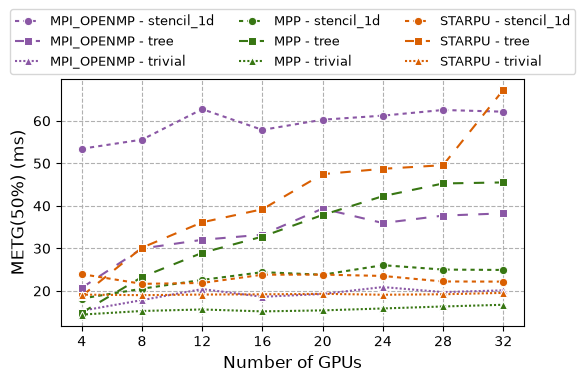

In [14]:
importlib.reload(utils)

# 1. FIX: Remove the '& type == @type' filter so it grabs all task graphs

types = ['stencil_1d', 'trivial', 'tree']

plot_df = metg_df.query(
    'type in @types'
).copy(deep=True)

plot_df['name'] = plot_df['name'].str.upper()

# 2. FIX: Create the combined column for the legend
plot_df['config_combo'] = plot_df['name'] + ' - ' + plot_df['type']

# 3. FIX: Map hue and style to the new combo column
plot_meta = utils.PlotMeta(
    x_axis='num_devices',
    y_axis='metg',
    hue='config_combo',    # <--- Uses combo column
    style='config_combo',  # <--- Uses combo column
    xlabel='Number of GPUs',
    ylabel='METG(50%) (ms)',
    xticks=plot_df['num_devices'].astype('str').unique(),
    yticks=[],
    legend_title='',
    legend_labels=[],
)

utils.generic_line_plot_err_bar_3(
    dataset=plot_df,
    title='',
    output_file=FIGURES_DIR/f'{DATE}_ws_metg.pdf', 
    plot_meta=plot_meta,
    dashes=True,
    fifty_percent_line=False,
    log_scale_y=False,
    outside_legend=True,
    tricolor_system=True,
)

### SSCAD 26

In [5]:
importlib.reload(utils)

scaling = 'ss'  # 'ws' for weak scaling, 'ss' for strong scaling
DATE = '140826'

benchs = [f'{DATE}_tb_gpu_ss_metg_{i}_workers' for i in range(1, 11)]

all_df = pd.concat([
    process_df(utils.load_data(DATA_DIR/f"{bench}.pkl")[0], i) for i, bench in enumerate(benchs, start=1) if (DATA_DIR/f"{bench}.pkl").exists()
])

all_df['devices_per_worker'] = all_df['dlist'].apply(lambda x: len(x.split(',')))
all_df['num_devices'] = all_df['devices_per_worker'] * all_df['workers']

all_df.drop(columns=['hosts', 'time', 'container', 'vcis', 'version', 'kernel'], inplace=True)
all_df['output'] = pd.to_numeric(all_df['output'], errors='coerce').fillna(4)

# all_df

# dev1_df = process_df(utils.load_data(DATA_DIR/"300326_mi210_ss_1_device_mpp.pkl")[0], 1)
# if 'total_tasks' not in dev1_df.columns:
#     dev1_df['total_tasks'] = 10 
# mpp_1dev_df = dev1_df.copy(deep=True)

# dev1_df = process_df(utils.load_data(DATA_DIR/"300326_mi210_ss_1_device_mpi.pkl")[0], 1)
# if 'total_tasks' not in dev1_df.columns:
#     dev1_df['total_tasks'] = 10 
# mpi_1dev_df = dev1_df.copy(deep=True)
# mpi_1dev_df['sys'] = 'mpi+openmp'

# all_df = pd.concat([all_df, mpp_1dev_df, mpi_1dev_df])

# agg_all_df = all_df.groupby(by=['sys', 'accl', 'devices', 'type', 'output', 'size', 'total_flops', 'total_tasks']).agg(
#     runtime_mean=('wall_time', 'mean'),
#     runtime_std=('wall_time', 'std')
# ).reset_index()




agg_all_df = all_df.copy(deep=True)
agg_all_df['runtime_mean'] = agg_all_df['wall_time']

agg_all_df['tflops_per_sec'] = agg_all_df['total_flops'] * np.pow(1/10, 12) / agg_all_df['runtime_mean']
agg_all_df['flops_per_task'] = agg_all_df['total_flops'] / agg_all_df['total_tasks']


agg_all_df_max_flops_per_device = agg_all_df.groupby(
    by=['name', 'num_devices', 'type', 'output'], as_index=False
)['tflops_per_sec'].max()


agg_all_df_max_flops_per_device.rename(columns={'tflops_per_sec': 'max_tflops_per_sec'}, inplace=True)
agg_all_df = agg_all_df.merge(agg_all_df_max_flops_per_device, on=['name', 'num_devices', 'type', 'output'])
agg_all_df['efficiency'] = agg_all_df['tflops_per_sec'] * 100 / agg_all_df['max_tflops_per_sec']
agg_all_df['task_granularity'] = agg_all_df['runtime_mean'] * agg_all_df['num_devices'] * np.pow(10, 3) / agg_all_df['total_tasks']
agg_all_df['size'] = 2**agg_all_df['size']
agg_all_df['output'] = 2**agg_all_df['output']
# agg_all_df['config'] = (
#     agg_all_df['sys'].str.upper()
# )

agg_all_df

metg_target = 'task_granularity'

metg = lambda x: utils.find_metg(x, x_data=metg_target, y_data='efficiency', method=2)

# # Get METG(50%)
metg_df = agg_all_df[['name', 'num_devices',  'output', 'type', metg_target, 'efficiency']].groupby(
    ['name', 'num_devices', 'output', 'type']).apply(metg, include_groups=False
).reset_index()

metg_df


,name,num_devices,output,type,metg
0,mpi_openmp,4,16,stencil_1d,12.001549
1,mpi_openmp,4,16,tree,14.606083
2,mpi_openmp,4,16,trivial,10.530608
3,mpi_openmp,8,16,stencil_1d,16.679893
4,mpi_openmp,8,16,tree,18.422492
...,...,...,...,...,...
67,starpu,28,16,tree,40.889471
68,starpu,28,16,trivial,14.173911
69,starpu,32,16,stencil_1d,16.263333
70,starpu,32,16,tree,50.006046


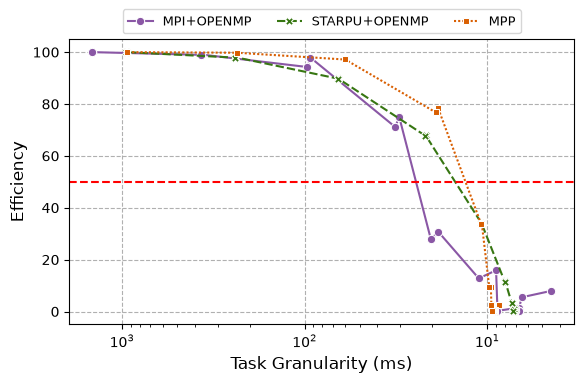

In [6]:
agg_all_df['name'] = agg_all_df['name'].apply(lambda name: 'MPI+OpenMP' if 'mpi' in name else name)
agg_all_df['name'] = agg_all_df['name'].apply(lambda name: 'STARPU+OpenMP' if 'starpu' in name else name)

agg_all_df['name'] = agg_all_df['name'].str.upper()
types = ['trivial']
num_devices = 32
plot_df = agg_all_df.query('type in @types & num_devices == @num_devices').copy(deep=True)

plot_df['config'] = plot_df['name'] + ' - ' + plot_df['type']


plot_meta = utils.PlotMeta(
    x_axis='task_granularity',
    y_axis='efficiency',
    hue='name',
    style='name',
    xlabel='Task Granularity (ms)',
    ylabel='Efficiency',
    xticks=[],
    yticks=[],
    legend_title='',
    legend_labels=[],
)

utils.generic_line_plot_err_bar_3(
    # dataset=df.query('workers == 1'),
    dataset=plot_df,
    title='',
    output_file=FIGURES_DIR/f'{DATE}_ws_trivial_metg.pdf',
    plot_meta=plot_meta,
    dashes=True,
    fifty_percent_line=True,
    log_scale=True,
    outside_legend=True,
    tricolor_system=False
)

In [14]:
utils.metg_relative_bar_subplots_2(
    dataset=metg_df,
    output_file=FIGURES_DIR/f'{DATE}_taskbench_ws_metg_relative.pdf',
    runtimes=['mpi_openmp', 'mpp', 'starpu'],
    patterns=['trivial', 'tree', 'stencil_1d'],
    num_devices=[4, 16, 32],
    output_value=16,
)


In [ ]:
utils.nbody_roofline(
    hip_stats_file=Path('hip_kernel_stats.csv'),
    hip_trace_file=Path('hip_kernel_trace.csv'),
    openmp_stats_file=Path('openmp_kernel_stats.csv'),
    openmp_trace_file=Path('openmp_kernel_trace.csv'),
    output_file=FIGURES_DIR/'130826_nbody_roofline_1gpu.pdf',
    n_bodies=2**20,
    num_gpus=1,
    reuse_source_position=True,
)
